# Interactive reservoir computing for chunking information streams

This notebook reproduces the mechanism of *Asabuki, T., Hiratani, N., & Fukai, T. (2018). Interactive reservoir computing for chunking information streams. PLOS Computational Biology, 14(10), e1006400.* <https://doi.org/10.1371/journal.pcbi.1006400>

Two reservoirs receive the same stream of letters. A fixed sequence of letters, the *chunk* (`a b c d`), comes back again and again, separated by random letters. Nobody tells the network where the chunk is. Each reservoir has a readout, and **each readout is trained to predict the normalised output of the other one**. The only thing both reservoirs can agree on is what is predictable in the stream, so both readouts end up responding to the chunk.

This is unsupervised, online learning, with a teacher signal that is itself produced by the model. ReservoirPy has no ready-made method for that, so this notebook also shows how to:

- write your own `Node` (a rate reservoir and a running normalisation);
- drive nodes one timestep at a time with `Node.step`;
- train a readout online with `RLS.partial_fit`.

It was rewritten for ReservoirPy v0.4. The previous version relied on `reservoirpy.experimental`, which no longer exists.

In [1]:
import string

import matplotlib.pyplot as plt
import numpy as np

import reservoirpy
from reservoirpy.node import Node
from reservoirpy.nodes import RLS

print(reservoirpy.__version__)

rng = np.random.default_rng(0)

0.4.3


## The input stream

Each letter is a channel. A letter is shown as a smooth pulse that rises for `width` timesteps and decays for `width` more, so consecutive letters overlap. The chunk `a b c d` alternates with sequences of 5 to 8 letters drawn at random from the 22 other letters.

`chunk_stream` also returns `in_chunk`, which is true while a letter of the chunk is being presented. It is only used to evaluate the result: the model never sees it.

In [2]:
def chunk_stream(n_timesteps, chunk=("a", "b", "c", "d"), width=50, input_gain=2.0, min_length=5):
    alphabet = tuple(string.ascii_lowercase)
    others = tuple(sorted(set(alphabet) - set(chunk)))

    t = np.arange(width)
    pulse = np.concatenate([input_gain * (1 - np.exp(-t / 10)), input_gain * np.exp(-t / 10)])

    def random_sequence():
        length = rng.integers(min_length, min_length + 4)
        return tuple(others[i] for i in rng.integers(0, len(others), length))

    X = np.zeros((n_timesteps, len(alphabet)))
    in_chunk = np.zeros(n_timesteps, dtype=bool)

    sequence, is_chunk, position = random_sequence(), False, 0
    for i in range(width, n_timesteps, width):
        if position == len(sequence) - 1:
            is_chunk = not is_chunk
            sequence, position = (chunk if is_chunk else random_sequence()), 0
        else:
            position += 1
        end = min(i + 2 * width, n_timesteps)
        X[i:end, alphabet.index(sequence[position])] = pulse[: end - i]
        in_chunk[i : min(i + width, n_timesteps)] = is_chunk

    return X, in_chunk

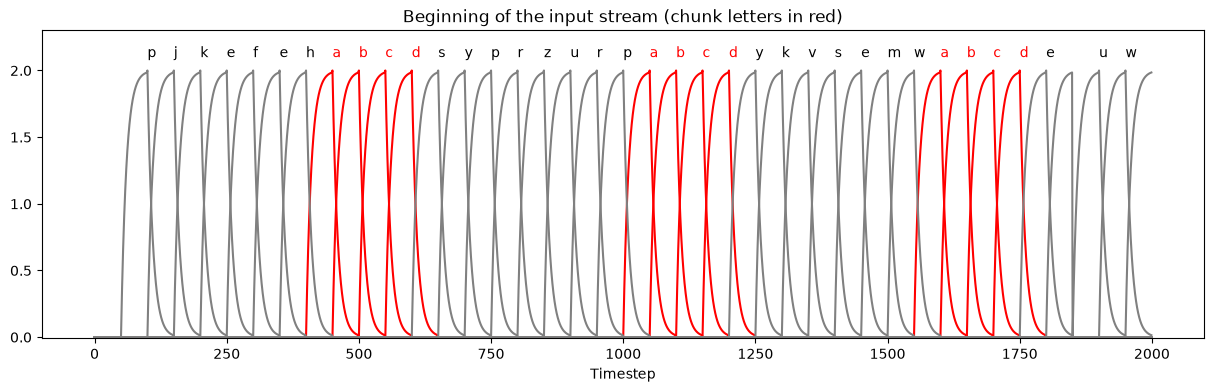

In [3]:
width = 50  # timesteps between two letters
train_len = 200_000
test_len = 4_000

X, in_chunk = chunk_stream(train_len + test_len, width=width)

samples = 2000
plt.figure(figsize=(15, 4))
plt.ylim(-0.01, 2.3)
for i in range(X.shape[1]):
    letter = string.ascii_lowercase[i]
    signal = X[:samples, i]
    if signal.sum() > 0.0:
        plt.plot(signal, color="red" if letter in "abcd" else "gray")
        for p in np.flatnonzero(np.isclose(signal, signal.max()) & (signal > 1.9)):
            plt.text(p, 2.1, letter, color="red" if letter in "abcd" else "black")
plt.xlabel("Timestep")
plt.title("Beginning of the input stream (chunk letters in red)")
plt.show()

## Two custom nodes

**A rate reservoir.** The paper uses a reservoir whose activation function is applied *after* the leaky integration, with noise on the membrane potential:

$$\mathbf{x}[t+1] = (1 - \mathrm{lr})\,\mathbf{x}[t] + \mathrm{lr}\,(\mathbf{W}\,\mathbf{r}[t] + \mathbf{W}_{in}\,\mathbf{u}[t+1]) + \sigma\,\xi, \qquad \mathbf{r}[t] = \tanh(\mathbf{x}[t])$$

`reservoirpy.nodes.Reservoir` applies the activation inside the integration, so we write this one ourselves. A node needs an `initialize` method, which creates its state, and a `_step` method, which maps a state and an input to a new state. The state is a dictionary; its `"out"` entry is the output of the node. Here the state also keeps the potential $\mathbf{x}$ under `"internal"`.

**A running normalisation.** The teacher signal is $\left[\tanh\left(\frac{z - \mu}{\beta\,\sigma}\right)\right]_+$, where $\mu$ and $\sigma$ are the mean and standard deviation of the readout output $z$ over a sliding window. The window is part of the node state.

In [4]:
class RateReservoir(Node):
    """Leaky reservoir with the activation function applied after integration."""

    def __init__(self, W, Win, lr=1.0, noise=0.0, seed=None, name=None):
        self.W = W
        self.Win = Win
        self.lr = lr
        self.noise = noise
        self.rng = np.random.default_rng(seed)
        self.name = name
        self.output_dim = W.shape[0]
        self.input_dim = Win.shape[1]

    def initialize(self, x=None, y=None):
        potential = 0.5 * self.rng.normal(size=self.output_dim)
        self.state = {"out": np.tanh(potential), "internal": potential}
        self.initialized = True

    def _step(self, state, x):
        potential = (1 - self.lr) * state["internal"] + self.lr * (self.W @ state["out"] + self.Win @ x)
        potential = potential + self.noise * self.rng.normal(size=potential.shape)
        return {"out": np.tanh(potential), "internal": potential}


class RunningNorm(Node):
    """Normalise a 1-dimensional signal with statistics from a sliding window."""

    def __init__(self, window, beta=3.0, name=None):
        self.window = window
        self.beta = beta
        self.name = name

    def initialize(self, x=None, y=None):
        self._set_input_dim(x)
        self.output_dim = self.input_dim
        self.state = {"out": np.zeros(self.output_dim), "store": np.zeros(self.window), "count": np.zeros((), dtype=int)}
        self.initialized = True

    def _step(self, state, x):
        store = state["store"].copy()
        count = int(state["count"])
        store[count % self.window] = x[0]
        sigma = max(store.std(), 1e-8)
        out = np.maximum(np.tanh((x - store.mean()) / (self.beta * sigma)), 0.0)
        return {"out": out, "store": store, "count": np.array(count + 1)}

## The model

Parameter values are those of the previous version of this notebook. One timestep is 1 ms.

In [5]:
dt = 1  # one timestep represents 1 ms
tau = 10  # time constant of the reservoir units
N = 300  # number of reservoir units
n = 300  # number of units read by each readout
g = 1.5  # gain of the recurrent weights
g_fb = 1.0  # gain of the feedback weights
alpha = 100  # RLS: P is initialised to identity / alpha
sigma = 0.3  # noise gain
window = 300  # normalisation window, in letters
beta = 3  # slope of the normalisation
learn_every = 2  # the readouts are trained every 2 timesteps

n_letters = X.shape[1]


def make_branch(seed):
    """A reservoir, its readout, the normalisation of the readout output, and the units the readout sees."""
    branch_rng = np.random.default_rng(seed)

    W = branch_rng.normal(size=(N, N)) * g / np.sqrt(N)

    # each unit listens to a single letter
    Win = np.zeros((N, n_letters))
    Win[np.arange(N), branch_rng.integers(0, n_letters, N)] = branch_rng.normal(size=N)

    # feedback of the readout into its own reservoir: one more input column
    Wfb = (branch_rng.random((N, 1)) - 0.5) * 2 * g_fb

    reservoir = RateReservoir(W, np.hstack([Win, Wfb]), lr=dt / tau, noise=sigma * np.sqrt(dt), seed=branch_rng)
    readout = RLS(alpha=alpha, Wout=branch_rng.normal(size=(n, 1)) / np.sqrt(n), fit_bias=False)
    norm = RunningNorm(window * width, beta=beta)
    seen_units = branch_rng.choice(N, n, replace=False)

    return reservoir, readout, norm, seen_units


branches = [make_branch(seed=1), make_branch(seed=2)]

## Training

At each timestep, for each of the two branches:

1. the reservoir receives the current letters and the previous output of its own readout;
2. the readout computes its output `z` from the reservoir units it sees;
3. the output is normalised.

Then each readout takes one RLS step towards **the normalised output of the other branch**.

The first `window * width` timesteps only fill the normalisation windows. With `train_len = 200_000` the loop takes one to two minutes. Selectivity improves with `train_len`: in our runs the correlation between a readout and the chunk went from 0.2-0.3 after 60 000 timesteps to 0.35-0.4 after 200 000.

In [6]:
transients = window * width
n_timesteps = len(X)

outputs = np.zeros((n_timesteps, 2))
z = [np.zeros(1), np.zeros(1)]

for t, u in enumerate(X):
    seen = []
    teachers = []
    for k, (reservoir, readout, norm, seen_units) in enumerate(branches):
        activity = reservoir.step(np.concatenate([u, z[k]]))[seen_units]
        z[k] = readout.step(activity)
        seen.append(activity)
        teachers.append(norm.step(z[k]))

    outputs[t] = z[0][0], z[1][0]

    if transients <= t < train_len and t % learn_every == 0:
        # partial_fit expects timeseries: [None] adds the time axis
        z[0] = branches[0][1].partial_fit(seen[0][None], teachers[1][None])[0]
        z[1] = branches[1][1].partial_fit(seen[1][None], teachers[0][None])[0]

## Result

The last `test_len` timesteps were not used for training. Both readouts rise when the chunk is presented (shaded), although no label was ever given.

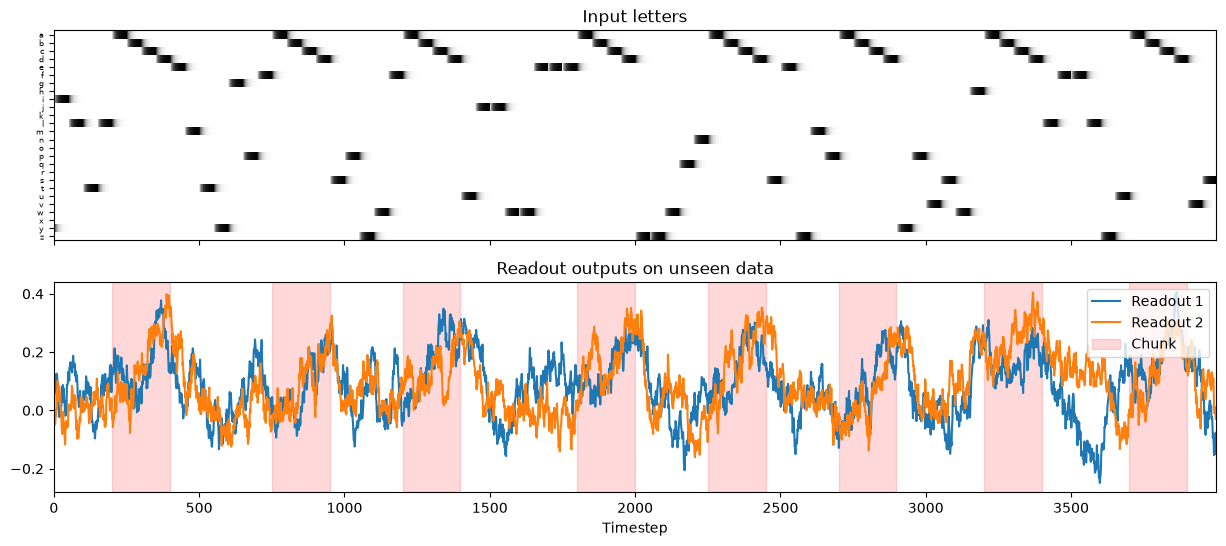

In [7]:
test = slice(train_len, n_timesteps)
time = np.arange(test_len)

fig, (ax0, ax1) = plt.subplots(2, 1, sharex=True, figsize=(15, 6))
ax0.imshow(X[test].T, aspect="auto", interpolation="none", cmap="gray_r")
ax0.set_yticks(range(n_letters), string.ascii_lowercase, fontsize=6)
ax0.set_title("Input letters")
ax1.plot(time, outputs[test, 0], label="Readout 1")
ax1.plot(time, outputs[test, 1], label="Readout 2")
ax1.fill_between(time, 0, 1, where=in_chunk[test], transform=ax1.get_xaxis_transform(), color="red", alpha=0.15, label="Chunk")
ax1.set_xlabel("Timestep")
ax1.set_title("Readout outputs on unseen data")
ax1.legend(loc="upper right")
plt.show()

In [8]:
for k in range(2):
    out = outputs[test, k]
    chunk = in_chunk[test]
    print(
        f"Readout {k + 1}: mean output {out[chunk].mean():.3f} during the chunk, "
        f"{out[~chunk].mean():.3f} outside; correlation with the chunk {np.corrcoef(out, chunk)[0, 1]:.2f}"
    )
print(f"Correlation between the two readouts: {np.corrcoef(outputs[test, 0], outputs[test, 1])[0, 1]:.2f}")

Readout 1: mean output 0.138 during the chunk, 0.053 outside; correlation with the chunk 0.39
Readout 2: mean output 0.143 during the chunk, 0.063 outside; correlation with the chunk 0.36
Correlation between the two readouts: 0.52


The correlation with the chunk marker understates the selectivity: the readouts respond with a lag, and the marker has sharp edges.

## Going further

- Increase `train_len` to 500 000, the value used by the previous version of this notebook.
- Change the chunk, or its length, and see what the readouts pick up.
- Set `sigma = 0` to see what the noise contributes.
- Train one readout on the chunk marker `in_chunk` with a supervised rule, and compare with what the pair learns without it.